---
title: plotting data exported from trios
author: kyle wodehouse
date: November 13, 2026
---

## Load data and shift factors

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, NullFormatter
from pathlib import Path
from math import floor, ceil, log10

R = 8.314  # J/(mol K)
BASE = Path(".")  # this notebook sits in the trios data folder
FIG_DIR = BASE / "figures"
FIG_DIR.mkdir(exist_ok=True)

POLYMERS = {
    "FEP": {
        "ref": 330,
        "shift_file": "FEP/FEP 9835 2007390112 mfr 24.8 330°C.txt",
        "sweeps": {
            330: "FEP/FEP 9835 2007390112 mfr 24.8 330°C.txt",
            350: "FEP/TE9835 Lot 2007390112 at 350°C.txt",
            370: "FEP/TE9835 Lot 2007390112 at 370°C.txt",
        },
    },
    "PFA 440HPAX": {
        "ref": 330,
        "shift_file": "PFA/PFA 440HPAX Lot 2103470009 at 330°C.txt",
        "sweeps": {
            330: "PFA/PFA 440HPAX Lot 2103470009 at 330°C.txt",
            350: "PFA/PFA 440  Lot 2103470009 mfr 15.5 at 350°C.txt",
            370: "PFA/PFA 440  Lot 2103470009 mfr 15.5 at 370°C.txt",
        },
    },
    "HT 2181": {
        "ref": 300,
        "shift_file": "HT/HT 2181 1212PASK 22 MFR 6,4 315°C.txt",
        "sweeps": {
            285: "HT/HT 2181 1212PASK 22 MFR 6,4 285°C.txt",
            300: "HT/HT 2181 1212PASK 22 MFR 6,4 300°C.txt",
            315: "HT/HT 2181 1212PASK 22 MFR 6,4 315°C.txt",
        },
    },
}


def _num(x):
    try:
        return float(x)
    except ValueError:
        return np.nan


def read_steps(path):
    """Split a TRIOS export into its steps, keeping the variable names and data rows."""
    steps, cur = [], None
    for line in Path(path).read_text(encoding="utf-8", errors="replace").splitlines():
        if line.startswith("Step name\t"):
            cur = {"name": line.split("\t", 1)[1], "vars": None, "rows": []}
            steps.append(cur)
        elif cur is None:
            continue
        elif line.startswith("Variables\t"):
            cur["vars"] = line.split("\t")[1:]
        elif line.startswith("Data point\t"):
            cur["rows"].append([_num(x) for x in line.split("\t")[1:]])
    return steps


def column(step, name):
    idx = step["vars"].index(name)
    return np.array([r[idx] for r in step["rows"]], float)


def load_sweep(path):
    step = next(s for s in read_steps(path) if s["name"].startswith("Frequency"))
    return column(step, "Angular frequency"), column(step, "Storage modulus"), column(step, "Loss modulus")


def load_shift_table(path):
    step = next(s for s in read_steps(path) if "shift" in s["name"].lower())
    T, aT = column(step, "Temperature"), column(step, "aT (x variable)")
    _, idx = np.unique(np.round(T), return_index=True)  # drops the duplicated 300 °C row in the HT table
    return T[idx], aT[idx]


DATA = {}
for name, cfg in POLYMERS.items():
    Tt, aTt = load_shift_table(cfg["shift_file"])
    sweeps = {T: load_sweep(f) for T, f in cfg["sweeps"].items()}
    aT = {T: aTt[np.argmin(np.abs(Tt - T))] for T in cfg["sweeps"]}
    DATA[name] = {"cfg": cfg, "Tt": Tt, "aTt": aTt, "sweeps": sweeps, "aT": aT}

for name, d in DATA.items():
    print(name, "| shift table T (°C):", d["Tt"], "| aT:", np.round(d["aTt"], 4))


FEP | shift table T (°C): [329.9967041  349.99960327 370.00039673] | aT: [1.     0.7415 0.5281]
PFA 440HPAX | shift table T (°C): [329.99362183 350.00091553 370.00415039] | aT: [1.     0.7352 0.5792]
HT 2181 | shift table T (°C): [284.98721313 299.99542236 314.99810791] | aT: [1.5399 1.     0.5548]


## Arrhenius fits of the shift factors

Fit ln a_T = intercept + slope/T with T in kelvin. Since ln a_T = (Ea/R)(1/T − 1/T_ref), the slope is Ea/R.

In [2]:
arrhenius = {}
for name, d in DATA.items():
    x = 1 / (d["Tt"] + 273.15)
    y = np.log(d["aTt"])
    slope, intercept = np.polyfit(x, y, 1)
    yfit = slope * x + intercept
    r2 = 1 - np.sum((y - yfit) ** 2) / np.sum((y - y.mean()) ** 2)
    # standard error of the slope (n - 2 dof), converted to Ea
    s_res = np.sqrt(np.sum((y - yfit) ** 2) / (len(x) - 2))
    se_slope = s_res / np.sqrt(np.sum((x - x.mean()) ** 2))
    ea_se = se_slope * R
    arrhenius[name] = {"slope": slope, "intercept": intercept, "r2": r2, "Ea": slope * R, "Ea_se": ea_se}
    print(f"{name}: Ea = {slope * R / 1000:.1f} ± {ea_se / 1000:.1f} kJ/mol (SE), R^2 = {r2:.4f}")


FEP: Ea = 51.4 ± 2.8 kJ/mol (SE), R^2 = 0.9970
PFA 440HPAX: Ea = 44.1 ± 2.4 kJ/mol (SE), R^2 = 0.9970
HT 2181: Ea = 92.7 ± 9.7 kJ/mol (SE), R^2 = 0.9892


## Plot helpers

In [3]:
def save_fig(fig, name, **kwargs):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=600, bbox_inches="tight", **kwargs)


def pure_decades(ax):
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(LogLocator(base=10.0, subs=(1.0,)))
        axis.set_minor_formatter(NullFormatter())


def safe(name):
    return name.replace(" ", "_")

## Shift factors with Arrhenius fits (one row, one panel per polymer)



In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=900)
legends = []
for ax, (name, d) in zip(axes, DATA.items()):
    fit = arrhenius[name]
    x = 1 / (d["Tt"] + 273.15)
    xx = np.linspace(x.min(), x.max(), 100)
    ax.plot(x * 1e3, np.log(d["aTt"]), "o", ms=7, mfc="C0", mec="k", ls="none", label=r"Shift factor $a_T$")
    ax.plot(xx * 1e3, fit["slope"] * xx + fit["intercept"], "-", color="k", lw=1.5, label=f"Arrhenius fit\n$E_a$ = {fit['Ea'] / 1000:.1f} ± {fit['Ea_se'] / 1000:.1f} kJ/mol")
    ax.set_xlabel(r"$1/T$ ($\times 10^{-3}$ K$^{-1}$)")
    ax.set_ylabel(r"$\ln a_T$")
    ax.set_title(name)
    legends.append(ax.legend(loc="upper left", frameon=False))
fig.subplots_adjust(wspace=0.35)
save_fig(fig, "shift_arrhenius_row", bbox_extra_artists=legends)
plt.show()


## Unshifted curves, one row per polymer

Raw G′ and G″ against ω, before the horizontal shift, for comparison with the master curves below.

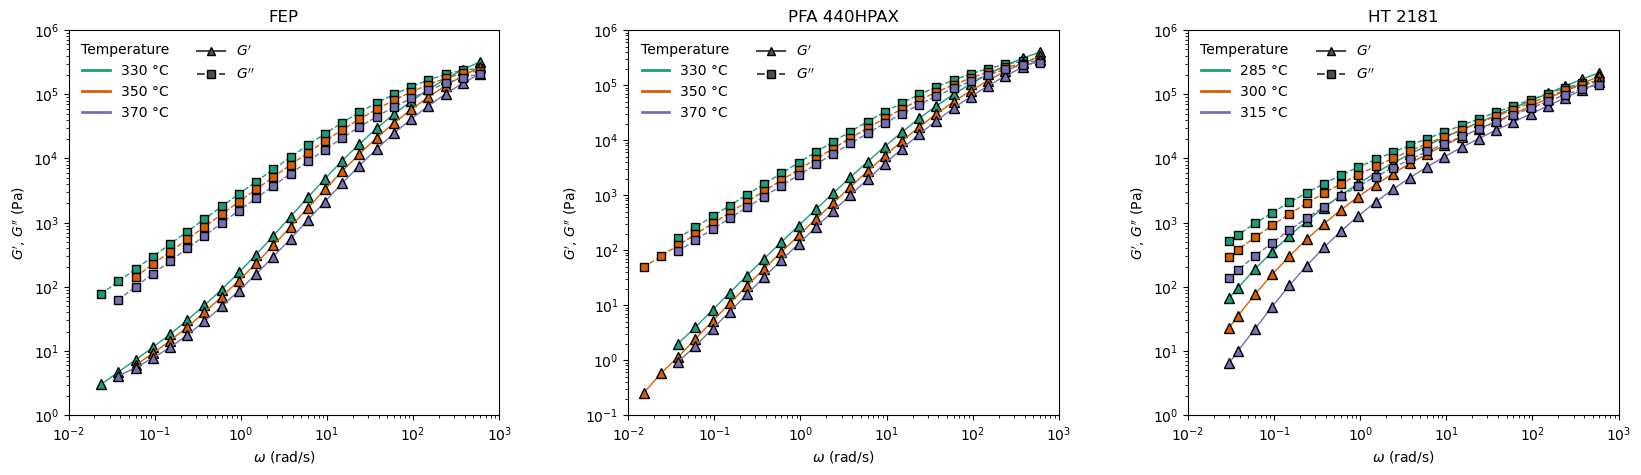

In [5]:
TEMP_COLORS = ["#1b9e77", "#d95f02", "#7570b3"]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
legends = []
for ax, (name, d) in zip(axes, DATA.items()):
    temp_handles, all_w, all_y = [], [], []
    for color, T in zip(TEMP_COLORS, sorted(d["sweeps"])):
        w, Gp, Gpp = d["sweeps"][T]
        Gp, Gpp = Gp * 1e6, Gpp * 1e6  # MPa -> Pa
        o = np.argsort(w)
        ax.plot(w[o], Gp[o], "^-", color=color, mfc=color, mec="k", ms=7, lw=1)
        ax.plot(w[o], Gpp[o], "s--", color=color, mfc=color, mec="k", ms=6, lw=1)
        temp_handles.append(Line2D([], [], color=color, lw=2, label=f"{T} °C"))
        all_w.append(w)
        all_y.extend([Gp, Gpp])

    ws = np.concatenate(all_w)
    ys = np.concatenate(all_y)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(10 ** floor(log10(ws.min())), 10 ** ceil(log10(ws.max())))
    ax.set_ylim(10 ** floor(log10(ys[ys > 0].min())), 10 ** ceil(log10(ys.max())))
    pure_decades(ax)

    ax.set_xlabel(r"$\omega$ (rad/s)")
    ax.set_ylabel(r"$G'$, $G''$ (Pa)")
    ax.set_title(name)

    qty_handles = [
        Line2D([], [], color="0.3", marker="^", ls="-", mfc="0.3", mec="k", label=r"$G'$"),
        Line2D([], [], color="0.3", marker="s", ls="--", mfc="0.3", mec="k", label=r"$G''$"),
    ]
    leg1 = ax.legend(handles=temp_handles, title="Temperature", loc="upper left", frameon=False)
    ax.add_artist(leg1)
    leg2 = ax.legend(handles=qty_handles, loc="upper left", bbox_to_anchor=(0.27, 1), frameon=False)
    legends.extend([leg1, leg2])

fig.subplots_adjust(wspace=0.3)
save_fig(fig, "unshifted_curves_row", bbox_extra_artists=legends)
plt.show()


## Master curves (shifted data), one row per polymer

x-axis is a_T·ω with the reference temperature for each polymer. Color is temperature; triangles/solid are G′ and squares/dashed are G″.

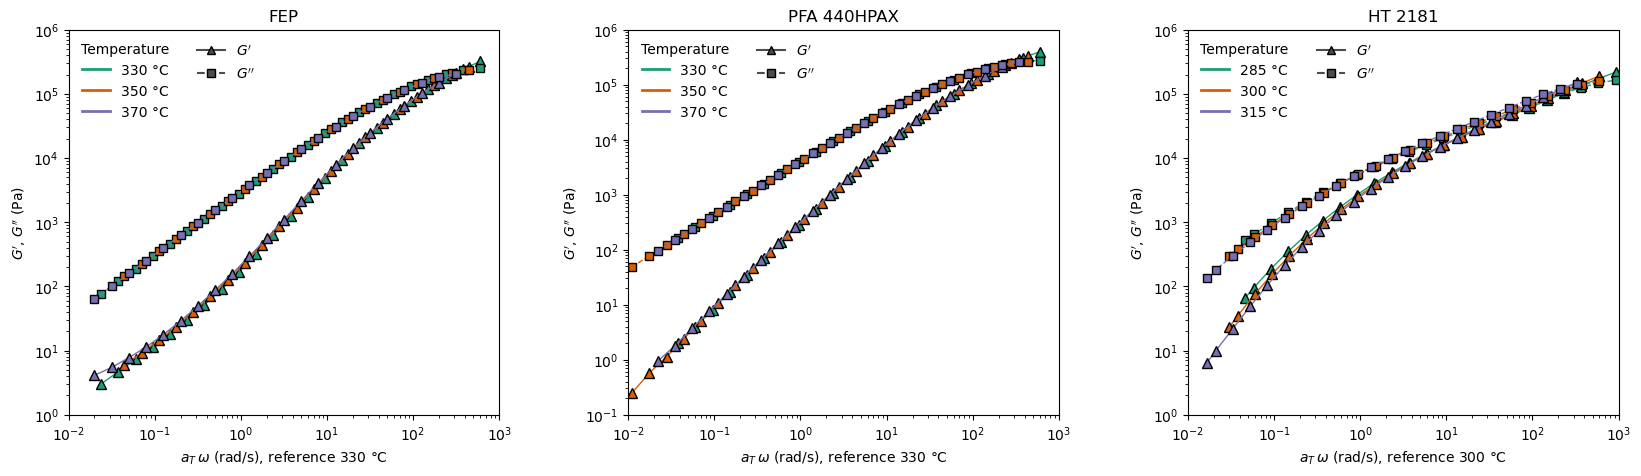

In [6]:
TEMP_COLORS = ["#1b9e77", "#d95f02", "#7570b3"]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
legends = []
for ax, (name, d) in zip(axes, DATA.items()):
    temp_handles, all_x, all_y = [], [], []
    for color, T in zip(TEMP_COLORS, sorted(d["sweeps"])):
        w, Gp, Gpp = d["sweeps"][T]
        Gp, Gpp = Gp * 1e6, Gpp * 1e6  # MPa -> Pa
        x = w * d["aT"][T]
        o = np.argsort(x)
        ax.plot(x[o], Gp[o], "^-", color=color, mfc=color, mec="k", ms=7, lw=1)
        ax.plot(x[o], Gpp[o], "s--", color=color, mfc=color, mec="k", ms=6, lw=1)
        temp_handles.append(Line2D([], [], color=color, lw=2, label=f"{T} °C"))
        all_x.append(x)
        all_y.extend([Gp, Gpp])

    xs = np.concatenate(all_x)
    ys = np.concatenate(all_y)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(10 ** floor(log10(xs.min())), 10 ** ceil(log10(xs.max())))
    ax.set_ylim(10 ** floor(log10(ys[ys > 0].min())), 10 ** ceil(log10(ys.max())))
    pure_decades(ax)

    ax.set_xlabel(rf"$a_T\,\omega$ (rad/s), reference {d['cfg']['ref']} °C")
    ax.set_ylabel(r"$G'$, $G''$ (Pa)")
    ax.set_title(name)

    qty_handles = [
        Line2D([], [], color="0.3", marker="^", ls="-", mfc="0.3", mec="k", label=r"$G'$"),
        Line2D([], [], color="0.3", marker="s", ls="--", mfc="0.3", mec="k", label=r"$G''$"),
    ]
    leg1 = ax.legend(handles=temp_handles, title="Temperature", loc="upper left", frameon=False)
    ax.add_artist(leg1)
    leg2 = ax.legend(handles=qty_handles, loc="upper left", bbox_to_anchor=(0.27, 1), frameon=False)
    legends.extend([leg1, leg2])

fig.subplots_adjust(wspace=0.3)
save_fig(fig, "master_curves_row", bbox_extra_artists=legends)
plt.show()

## Cross model fits to shifted complex viscosity (one row per polymer)

Shifted viscosity: η_ref = η*·b_T/a_T with b_T = T_ref/T (kelvin), assuming density ratio 1. |η_ref| = η0 / (1 + (λ·a_T·ω)^m) is fit in log space.

excluded FEP 370 °C angular frequencies (rad/s): [0.0379]
===== FEP =====
         param       best     stderr  rel.err   95% CI (profile)        
------------------------------------------------------------------------
   eta0 (Pa·s)       3044       19.8    0.65%   [3004, 3085]            
    lambda (s)    0.01032  0.0003288    3.19%   [0.009672, 0.01103]     
             m     0.6845    0.01379    2.01%   [0.6563, 0.7136]        

N = 65, free params = 3, chi-square = 0.05781, reduced chi-square = 0.000932 (residual s.d. in ln units = 0.0305)

===== PFA 440HPAX =====
         param       best     stderr  rel.err   95% CI (profile)        
------------------------------------------------------------------------
   eta0 (Pa·s)       4214      22.83    0.54%   [4168, 4261]            
    lambda (s)    0.01317  0.0003558    2.70%   [0.01246, 0.01393]      
             m      0.692    0.01071    1.55%   [0.6702, 0.7143]        

N = 68, free params = 3, chi-square = 0.04652, reduced 

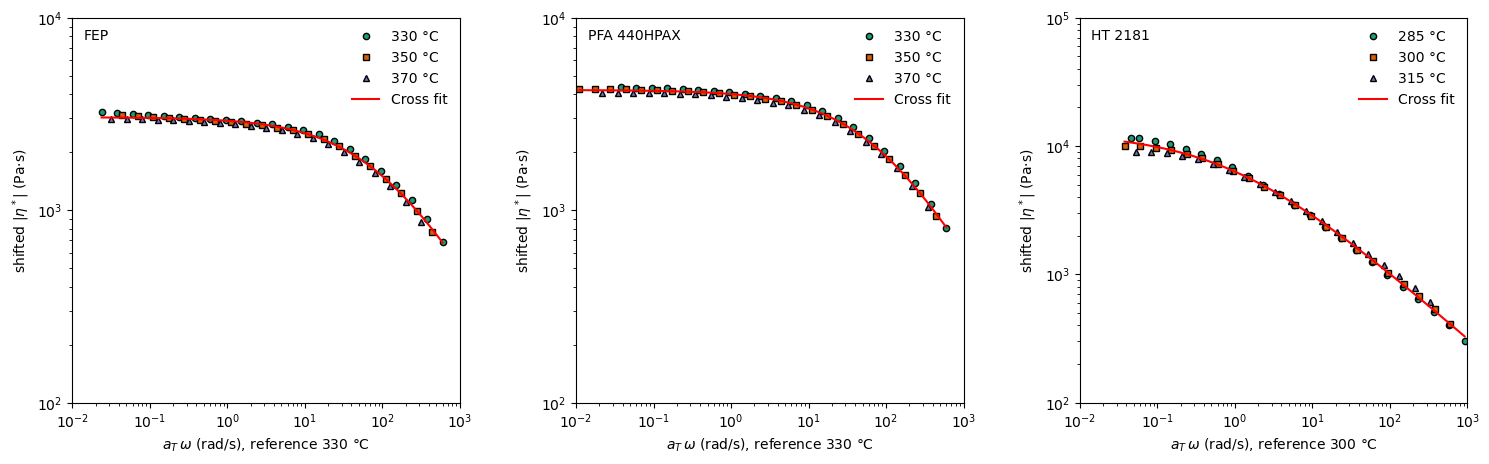

In [7]:
import lmfit


def cross(x, eta0, lam, m):
    return eta0 / (1 + (lam * x) ** m)


def log_cross(lx, leta0, llam, m):
    return np.log(np.exp(leta0) / (1 + (np.exp(llam) * np.exp(lx)) ** m))


def load_eta(path):
    step = next(s for s in read_steps(path) if s["name"].startswith("Frequency"))
    return column(step, "Complex viscosity")


# Sweeps run from high to low frequency, so the lowest-frequency points are measured
# last, 10-35 min into the test. In the terminal region |eta*| should level off as
# omega drops. A point that falls below the highest |eta*| already measured at higher
# frequency means the sample changed during the test (most likely degradation), so it
# is dropped. DROP_TOL keeps sub-1% point-to-point noise from triggering the rule.
DROP_TOL = 0.01


def degraded_points(w, eta, tol=DROP_TOL):
    """Boolean mask of points whose |eta*| is more than tol below the running maximum
    taken from high to low frequency (uses the raw, unshifted |eta*|)."""
    order = np.argsort(w)[::-1]
    running_max = np.maximum.accumulate(eta[order])
    bad = np.zeros_like(w, bool)
    bad[order] = eta[order] < (1 - tol) * running_max
    return bad


TEMP_SHAPES = ["o", "s", "^"]
cross_fits = {}


def fmt(x, nd=4):
    # compact number formatting that survives None/inf/nan
    if x is None or not np.isfinite(x):
        return "n/a"
    return f"{x:.{nd}g}"


def ci_bounds(ci, name):
    # lmfit returns (probability, value) pairs: the best value has probability 0, the bounds ~0.9545
    pairs = ci[name]
    val = next(v for pr, v in pairs if pr == 0)
    lo = next(v for pr, v in pairs if pr > 0 and v < val)
    hi = next(v for pr, v in pairs if pr > 0 and v > val)
    return lo, val, hi


def summarize_cross(name, result, ci):
    """Best fit, stderr, relative error and 95% profile CI on the natural scale (eta0 and lambda were fitted in log space)."""
    print(f"===== {name} =====")
    head = f"{'param':>14} {'best':>10} {'stderr':>10} {'rel.err':>8}   {'95% CI (profile)':<24}"
    print(head)
    print("-" * len(head))
    for key, label in [("leta0", "eta0 (Pa·s)"), ("llam", "lambda (s)"), ("m", "m")]:
        p = result.params[key]
        lo, _, hi = ci_bounds(ci, key)
        if key == "m":
            best, se, lo_n, hi_n = p.value, p.stderr, lo, hi
            rel = 100 * se / abs(best)
        else:
            best = np.exp(p.value)
            se = best * p.stderr
            lo_n, hi_n = np.exp(lo), np.exp(hi)
            rel = 100 * p.stderr
        ci_txt = f"[{fmt(lo_n)}, {fmt(hi_n)}]"
        print(f"{label:>14} {fmt(best):>10} {fmt(se):>10} {rel:7.2f}%   {ci_txt:<24}")
    print(f"\nN = {result.ndata}, free params = {result.nvarys}, chi-square = {result.chisqr:.4g}, "
          f"reduced chi-square = {result.redchi:.3g} (residual s.d. in ln units = {np.sqrt(result.redchi):.3g})")
    # if result.covar is not None:
    #     print("\nCorrelation matrix (leta0 = ln eta0, llam = ln lambda):")
    #     names = result.var_names
    #     sd = np.sqrt(np.diag(result.covar))
    #     corr = result.covar / np.outer(sd, sd)
    #     print(" " * 9 + "".join(f"{n:>9}" for n in names))
    #     for i, n in enumerate(names):
    #         print(f"{n:>9}" + "".join(f"{corr[i, j]:9.3f}" for j in range(len(names))))
    print()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
legends = []
for ax, (name, d) in zip(axes, DATA.items()):
    temp_handles, all_x, all_eta = [], [], []
    for color, shape, T in zip(TEMP_COLORS, TEMP_SHAPES, sorted(d["sweeps"])):
        w, _, _ = d["sweeps"][T]
        eta = load_eta(d["cfg"]["sweeps"][T])
        eta = eta * ((d["cfg"]["ref"] + 273.15) / (T + 273.15)) / d["aT"][T]  # vertical shift b_T / a_T
        drop = np.flatnonzero(degraded_points(w, load_eta(d["cfg"]["sweeps"][T])))
        if drop.size:
            print(f"excluded {name} {T} °C angular frequencies (rad/s):", np.round(w[drop], 4))
            eta = np.delete(eta, drop)
            w = np.delete(w, drop)
        x = w * d["aT"][T]
        o = np.argsort(x)
        ax.plot(x[o], eta[o], shape, color=color, mfc=color, mec="k", ms=4.5, ls="none")
        temp_handles.append(Line2D([], [], color=color, marker=shape, mfc=color, mec="k", ms=4.5, ls="none", label=f"{T} °C"))
        all_x.append(x)
        all_eta.append(eta)

    x_all = np.concatenate(all_x)
    eta_all = np.concatenate(all_eta)
    ok = (x_all > 0) & (eta_all > 0) & np.isfinite(eta_all)
    x_ok, eta_ok = x_all[ok], eta_all[ok]

    lmodel = lmfit.Model(log_cross, independent_vars=["lx"])
    params = lmodel.make_params(leta0=np.log(eta_ok.max()), llam=np.log(1 / np.median(x_ok)), m=0.8)
    params["m"].set(min=0.05, max=1.5)
    result = lmodel.fit(np.log(eta_ok), params, lx=np.log(x_ok))

    # 95% profile-likelihood confidence intervals (log-scale parameters for eta0 and lambda)
    ci = lmfit.conf_interval(result, result, sigmas=(2,))
    def bounds(name):
        pairs = ci[name]  # (probability, value): best value has probability 0, bounds have ~0.9545
        val = next(v for pr, v in pairs if pr == 0)
        lo = next(v for pr, v in pairs if pr > 0 and v < val)
        hi = next(v for pr, v in pairs if pr > 0 and v > val)
        return lo, val, hi
    le_lo, le_v, le_hi = bounds("leta0")
    ll_lo, ll_v, ll_hi = bounds("llam")
    m_lo, m_v, m_hi = bounds("m")
    eta0, eta0_lo, eta0_hi = np.exp(le_v), np.exp(le_lo), np.exp(le_hi)
    lam, lam_lo, lam_hi = np.exp(ll_v), np.exp(ll_lo), np.exp(ll_hi)
    m = m_v

    pred = np.log(cross(x_ok, eta0, lam, m))
    r2 = 1 - np.sum((np.log(eta_ok) - pred) ** 2) / np.sum((np.log(eta_ok) - np.log(eta_ok).mean()) ** 2)
    cross_fits[name] = {"eta0": eta0, "eta0_ci": (eta0_lo, eta0_hi), "lam": lam, "lam_ci": (lam_lo, lam_hi),
                        "m": m, "m_ci": (m_lo, m_hi), "r2": r2, "n": len(x_ok)}
    summarize_cross(name, result, ci)

    xx = np.logspace(np.log10(x_ok.min()), np.log10(x_ok.max()), 200)
    ax.plot(xx, cross(xx, eta0, lam, m), "-", color="red", lw=1.5)
    handles = temp_handles + [Line2D([], [], color="red", lw=1.5, label="Cross fit")]

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(10 ** floor(log10(x_ok.min())), 10 ** ceil(log10(x_ok.max())))
    ax.set_ylim(10 ** floor(log10(eta_ok.min())), 10 ** ceil(log10(eta_ok.max())))
    pure_decades(ax)
    ax.set_xlabel(rf"$a_T\,\omega$ (rad/s), reference {d['cfg']['ref']} °C")
    ax.set_ylabel(r"shifted $|\eta^*|$ (Pa·s)")
    ax.text(0.03, 0.97, name, transform=ax.transAxes, ha="left", va="top")
    legends.append(ax.legend(handles=handles, loc="upper right", frameon=False))

fig.subplots_adjust(wspace=0.3)
save_fig(fig, "cross_viscosity_row", bbox_extra_artists=legends)
plt.show()


## Cross model prediction table

One row per polymer. Predict |η*| (Pa·s) at angular frequency ω (rad/s) and temperature T (°C) with:

- a_T = exp[(Ea/R)(1/T − 1/T_ref)] (T in kelvin)
- b_T = T_ref/T (kelvin)
- |η*| = (a_T / b_T) · η0 / (1 + (λ·a_T·ω)^m)

Valid for the sweep temperature range and shifted frequency range listed below; the Arrhenius fit for HT 2181 uses only three temperatures.

Table: Cross model parameters for each polymer. ± values are 95% confidence intervals (half-widths shown).

In [8]:
import pandas as pd


def aT_of_T(name, T_C):
    """Shift factor from the Arrhenius relation, referenced to T_ref."""
    T_ref = DATA[name]["cfg"]["ref"]
    Ea = arrhenius[name]["Ea"]
    return np.exp(Ea / R * (1 / (T_C + 273.15) - 1 / (T_ref + 273.15)))


def cross_predict(name, T_C, omega):
    """|eta*| (Pa.s) at angular frequency omega (rad/s) and temperature T_C (deg C)."""
    cf = cross_fits[name]
    T_ref = DATA[name]["cfg"]["ref"]
    aT = aT_of_T(name, T_C)
    bT = (T_ref + 273.15) / (T_C + 273.15)
    x = aT * np.asarray(omega, float)
    return (aT / bT) * cf["eta0"] / (1 + (cf["lam"] * x) ** cf["m"])


rows = []


def pm(value, lo, hi, fmt):
    """Value ± half-width of the 95% confidence interval."""
    return f"{format(value, fmt)} ± {format((hi - lo) / 2, fmt)}"


for name, d in DATA.items():
    fit, cf = arrhenius[name], cross_fits[name]
    w_shift = np.concatenate([d["sweeps"][T][0] * d["aT"][T] for T in d["sweeps"]])
    rows.append({
        "polymer": name,
        "T_ref (°C)": d["cfg"]["ref"],
        "Ea (kJ/mol)": f"{fit['Ea'] / 1000:.1f}",
        "η0 (Pa·s)": pm(cf["eta0"], *cf["eta0_ci"], ".0f"),
        "λ (s)": pm(cf["lam"], *cf["lam_ci"], ".4f"),
        "m": pm(cf["m"], *cf["m_ci"], ".3f"),
        "shifted ω range (rad/s)": f"{w_shift.min():.3g} – {w_shift.max():.3g}",
    })

table = pd.DataFrame(rows).set_index("polymer")
table.to_csv(BASE / "cross_model_parameters.csv")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print(table.to_string())

# LaTeX version of the table (booktabs), written next to the notebook
tex_headers = [
    r"$T_{\mathrm{ref}}$ ($^\circ$C)",
    r"$E_a$ (kJ/mol)",
    r"$\eta_0$ (Pa$\cdot$s)",
    r"$\lambda$ (s)",
    r"$m$",
    r"shifted $\omega$ range (rad/s)",
]


def tex_cell(s):
    return str(s).replace(" ± ", r" $\pm$ ").replace(" – ", "--")


tex_lines = [
    r"\begin{table}[htbp]",
    r"\centering",
    r"\begin{tabular}{l" + "c" * len(tex_headers) + "}",
    r"\toprule",
    " & ".join(["Polymer"] + tex_headers) + r" \\",
    r"\midrule",
]
for pol, row in table.iterrows():
    tex_lines.append(" & ".join([pol] + [tex_cell(row[c]) for c in table.columns]) + r" \\")
tex_lines += [
    r"\bottomrule",
    r"\end{tabular}",
    r"\caption{Cross model parameters for each polymer, with $a_T$ and $b_T$ defined relative to $T_{\mathrm{ref}}$. Values with $\pm$ are 95\% confidence intervals (half-widths shown).}",
    r"\label{tab:cross_model_parameters}",
    r"\end{table}",
]
tex_path = BASE / "cross_model_parameters.tex"
tex_path.write_text("\n".join(tex_lines) + "\n", encoding="utf-8")
# print("\n".join(tex_lines))

# check predictions against measured |eta*| at each sweep temperature
print()
for name, d in DATA.items():
    errs = []
    for T in sorted(d["sweeps"]):
        w = d["sweeps"][T][0]
        eta = load_eta(d["cfg"]["sweeps"][T])
        pred = cross_predict(name, T, w)
        errs.append(np.median(np.abs(pred / eta - 1)))
    print(f"{name}: median |predicted/measured - 1| at each sweep T:", np.round(errs, 3))


             T_ref (°C) Ea (kJ/mol)    η0 (Pa·s)            λ (s)              m shifted ω range (rad/s)
polymer                                                                                                 
FEP                 330        51.4    3044 ± 41  0.0103 ± 0.0007  0.685 ± 0.029              0.02 – 600
PFA 440HPAX         330        44.1    4214 ± 47  0.0132 ± 0.0007  0.692 ± 0.022            0.0111 – 600
HT 2181             300        92.7  12780 ± 725  1.0345 ± 0.2427  0.529 ± 0.015            0.0166 – 924

FEP: median |predicted/measured - 1| at each sweep T: [0.035 0.023 0.032]
PFA 440HPAX: median |predicted/measured - 1| at each sweep T: [0.032 0.022 0.031]
HT 2181: median |predicted/measured - 1| at each sweep T: [0.077 0.017 0.075]
